In [1]:
# ============================================================
# Cell 1. Setup: imports, seeds, device, plot helpers
# ============================================================
import csv
import os
import random
import time

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
from scipy import optimize, special

OUT_DIR = "./results"                # directory for table2.tex, table2.csv, and optional figure
SEED = 2026
MASTER_SEED = 20261019               # root seed ensuring exact reproduction of Table II
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float64

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

os.makedirs(OUT_DIR, exist_ok=True)
print(f"torch {torch.__version__}, device {DEVICE}, dtype {DTYPE}")


def set_plot_style():
    matplotlib.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.size": 12, "axes.labelsize": 13, "legend.fontsize": 9.5,
        "xtick.labelsize": 11, "ytick.labelsize": 11,
        "axes.unicode_minus": False,
        "ps.fonttype": 42, "pdf.fonttype": 42,
    })

torch 2.2.2, device cuda, dtype torch.float64


In [2]:
# ============================================================
# Cell 2. Stationary theoretical references for M = 1, theta_1 = 0, N = 31
# ============================================================
N_EL = 31
SQRT2, SQRT2PI = np.sqrt(2.0), np.sqrt(2.0 * np.pi)


def gauss_expect(f, n=200):
    z, wq = np.polynomial.hermite_e.hermegauss(n)
    return float(np.sum(wq * f(z)) / SQRT2PI)


def sine_expect(f, n=800):
    u, wq = np.polynomial.legendre.leggauss(n)
    return float(0.5 * np.sum(wq * f(SQRT2 * np.sin(0.5 * np.pi * u))))


def stationary_refs(expect, N=N_EL):
    hb = lambda x, s: special.erf(x / (s * SQRT2))
    hp = lambda x, s: -2.0 * x / s ** 2 * np.exp(-0.5 * (x / s) ** 2) / SQRT2PI
    power = expect(lambda x: x * x)
    p = lambda s: expect(lambda x: x * hb(x, s))
    psi = lambda s: expect(lambda x: hb(x, s) ** 2)
    zeta = lambda s: power - N * p(s) ** 2 / (1.0 + (N - 1) * psi(s))
    drift = lambda s: (expect(lambda x: x * hp(x, s)) * (1.0 + (N - 1) * psi(s))
                       - 0.5 * N * p(s) * 2.0 * expect(lambda x: hb(x, s) * hp(x, s)))
    s_o = optimize.minimize_scalar(zeta, bounds=(0.05, 5.0), method="bounded",
                                   options={"xatol": 1e-10}).x
    s_d = optimize.brentq(drift, 0.05, 5.0, xtol=1e-12)
    return dict(sigma_o=float(s_o), sigma_dag=float(s_d),
                zeta_o=zeta(s_o), zeta_dag=zeta(s_d))


REF = {"gauss": stationary_refs(gauss_expect), "sine": stationary_refs(sine_expect)}
for key, label in (("gauss", "Gaussian input"), ("sine", "Sinusoidal input")):
    r = REF[key]
    print(f"{label:17s} (N = {N_EL}): sigma^o = {r['sigma_o']:.4f}, sigma^* = {r['sigma_dag']:.4f}; "
          f"NMSE zeta(sigma^o) = {r['zeta_o']:.4f}, zeta(sigma^*) = {r['zeta_dag']:.4f}")

Gaussian input    (N = 31): sigma^o = 1.0073, sigma^* = 1.1164; NMSE zeta(sigma^o) = 0.1029, zeta(sigma^*) = 0.1046
Sinusoidal input  (N = 31): sigma^o = 0.7233, sigma^* = 0.8366; NMSE zeta(sigma^o) = 0.0381, zeta(sigma^*) = 0.0403


In [3]:
# ============================================================
# Cell 3. PyTorch simulator for RLS--EKF, Gradient, and Fixed sigma
# ============================================================
THETAS, NS = (0.0,), (N_EL,)
R_W, P0_W, W0 = 0.01, 31.0, 0.0      # RLS parameters: lambda_w = 0.01, P_0 = 31, w_0 = 0
SIGMA0 = 0.5                         # initial noise scale
Q_SIGMA, R_SIGMA, P0_SIGMA = 1e-1, 1.0, 2.0
LOG_CLIP = 1.0
SIGMA_FLOOR = 1e-6


def dither_to_device(xi):
    return torch.as_tensor(np.asarray(xi, dtype=np.float32)).to(DEVICE).permute(1, 0, 2).contiguous()


def _rows(v, B):
    return torch.as_tensor(np.broadcast_to(np.asarray(v, dtype=np.float64), (B,)).copy(),
                           dtype=DTYPE, device=DEVICE)


@torch.no_grad()
def simulate(x, xi_t, rule, lam_f=1.0, sigma0=SIGMA0, sigma_fixed=None, mu=None,
             Q=Q_SIGMA, R=R_SIGMA, P0s=P0_SIGMA, thetas=THETAS, Ns=NS,
             x_idx=None, xi_idx=None, record_xhat=True, record_sigma=False, seg_bounds=None):
    if rule not in ("ekf", "grad", "fixed"):
        raise ValueError(f"Unsupported rule: {rule}")
    x = np.atleast_2d(np.asarray(x, dtype=np.float64))
    S, K = x.shape
    if x_idx is None and xi_idx is not None:
        x_idx = np.arange(S)
    B = S if x_idx is None else len(x_idx)
    xs = torch.as_tensor(x.T.copy(), dtype=DTYPE, device=DEVICE)
    xr = None if x_idx is None else torch.as_tensor(np.asarray(x_idx), dtype=torch.long, device=DEVICE)
    xi_rows = x_idx if xi_idx is None else xi_idx
    ir = None if xi_rows is None else torch.as_tensor(np.asarray(xi_rows), dtype=torch.long, device=DEVICE)

    M = len(Ns)
    gavg = np.zeros((int(sum(Ns)), M))
    a = 0
    for m, n_m in enumerate(Ns):
        gavg[a:a + n_m, m] = 1.0 / n_m
        a += n_m
    Gavg = torch.as_tensor(gavg, dtype=DTYPE, device=DEVICE)
    th_el = torch.as_tensor(np.repeat(np.asarray(thetas, float), Ns), dtype=DTYPE, device=DEVICE)
    th_g = torch.as_tensor(np.asarray(thetas, float), dtype=DTYPE, device=DEVICE)
    Nm = torch.as_tensor(np.asarray(Ns, float), dtype=DTYPE, device=DEVICE)

    lam = _rows(lam_f, B)
    w = torch.full((B, M), float(W0), dtype=DTYPE, device=DEVICE)
    P = torch.eye(M, dtype=DTYPE, device=DEVICE).expand(B, M, M).clone() * P0_W
    tr_cap = M * P0_W
    sigma = _rows(sigma_fixed if rule == "fixed" else sigma0, B)
    mu_b = _rows(0.0 if mu is None else mu, B)
    Q_b, R_b = _rows(Q, B), _rows(R, B)
    Ps = _rows(P0s, B)
    failed = torch.zeros(B, dtype=torch.bool, device=DEVICE)
    xhat_t = torch.empty((K, B), dtype=torch.float32, device=DEVICE) if record_xhat else None
    sig_t = torch.empty((K, B), dtype=torch.float32, device=DEVICE) if record_sigma else None

    seg_of = np.full(K, -1)
    if seg_bounds is not None:
        for j, (sa, sb) in enumerate(seg_bounds):
            seg_of[sa:sb] = j
        seg_err = torch.zeros((len(seg_bounds), B), dtype=DTYPE, device=DEVICE)
        seg_pow = torch.zeros((len(seg_bounds), B), dtype=DTYPE, device=DEVICE)

    for k in range(K):
        xk = xs[k] if xr is None else xs[k][xr]
        xik = xi_t[k] if ir is None else xi_t[k][ir]
        s = torch.sign(xk[:, None] + sigma[:, None] * xik.to(DTYPE) - th_el) @ Gavg
        xh = (w * s).sum(-1)
        eps = xk - xh
        if record_xhat:
            xhat_t[k] = xh
        if record_sigma:
            sig_t[k] = sigma
        if seg_of[k] >= 0:
            seg_err[seg_of[k]] += eps * eps
            seg_pow[seg_of[k]] += xk * xk

        # RLS weight update with exponential forgetting
        Psv = (P @ s[:, :, None])[:, :, 0]
        g = Psv / ((s * Psv).sum(-1) + lam * R_W)[:, None]
        w_prev = w
        w = w + g * eps[:, None]
        P = (P - g[:, :, None] * Psv[:, None, :]) / lam[:, None, None]
        P = 0.5 * (P + P.transpose(1, 2))
        tr = torch.diagonal(P, dim1=1, dim2=2).sum(-1)
        P = P * torch.clamp(tr_cap / tr, max=1.0)[:, None, None]

        # Noise-scale update
        if rule == "fixed":
            continue
        ss = torch.clamp(sigma, min=SIGMA_FLOOR)
        u = (xk[:, None] - th_g) / ss[:, None]
        hb = torch.erf(u / SQRT2)
        hp = -2.0 * u * torch.exp(-0.5 * u * u) / (SQRT2PI * ss[:, None])
        if rule == "ekf":
            H = (w_prev * hp).sum(-1)
            Kg = Ps * H / (H * H * Ps + R_b)
            sig_new = sigma + Kg * eps
            Ps = (1.0 - Kg * H) * Ps + Q_b
        else:
            resid = xk - (w_prev * hb).sum(-1)
            dloss = (-2.0 * resid * (w_prev * hp).sum(-1)
                     - 2.0 * (w_prev * w_prev / Nm * hb * hp).sum(-1))
            sig_new = sigma * torch.exp(torch.clamp(-mu_b * sigma * dloss, min=-LOG_CLIP, max=LOG_CLIP))
        bad = ~torch.isfinite(sig_new) | (sig_new <= 0)
        failed = failed | bad
        sigma = torch.where(bad, torch.clamp(sigma.abs(), min=SIGMA_FLOOR), sig_new)

    return dict(xhat=None if xhat_t is None else xhat_t.T.cpu().numpy(),
                sigma=None if sig_t is None else sig_t.T.cpu().numpy(),
                seg_err=None if seg_bounds is None else seg_err.T.cpu().numpy(),
                seg_pow=None if seg_bounds is None else seg_pow.T.cpu().numpy(),
                failed=failed.cpu().numpy())

In [4]:
# ============================================================
# Cell 4. Stream generators, parameter tuning, and LM quantizer
# ============================================================
N_WARM, N_ONLINE, CHANGE = 1000, 3000, 1500
TRIALS = 20

# Only the 6 test cases reported in Table II
CASES = (
    ("Gauss", "gauss", 1.0),
    ("Sine", "sine", 1.0),
    ("A=0.1", "gauss", 0.1),
    ("A=0.5", "gauss", 0.5),
    ("A=2", "gauss", 2.0),
    ("A=10", "gauss", 10.0),
)
DEV_STEPS = (0.1, 0.2, 1 / 3, 3.0, 5.0, 10.0)
LAM_GRID = (0.8, 0.85, 0.9, 0.93, 0.95, 0.97, 0.98, 0.99, 0.995, 0.998, 1.0)

METHODS = {
    "RLS--EKF": ("ekf", {"Q": np.logspace(-4, 0, 9)}),
    "Gradient": ("grad", {"mu": np.logspace(-4, 1, 21)}),
    "Fixed $\\sigma$": ("fixed", {"sigma_fixed": np.logspace(-1, 1.3, 47)}),
}


def child_rngs(tag, n):
    return [np.random.default_rng(c) for c in np.random.SeedSequence([MASTER_SEED, tag]).spawn(n)]


def dev_streams(steps, tag=11):
    xs, xis = [], []
    for r, A in zip(child_rngs(tag, len(steps)), steps):
        z = r.standard_normal(N_WARM + N_ONLINE)
        xs.append(z * np.where(np.arange(N_WARM + N_ONLINE) < N_WARM + CHANGE, 1.0, A))
        xis.append(r.standard_normal((N_WARM + N_ONLINE, N_EL), dtype=np.float32))
    return np.stack(xs), np.stack(xis)


def test_streams(cases, n_trials=TRIALS, tag=20):
    K = N_WARM + N_ONLINE
    rngs = child_rngs(tag, n_trials)
    z = np.stack([r.standard_normal(K) for r in rngs])
    v = np.stack([SQRT2 * np.sin(r.uniform(0.0, 2.0 * np.pi, K)) for r in rngs])
    xi = np.stack([r.standard_normal((K, N_EL), dtype=np.float32) for r in rngs])
    gain = lambda A: np.where(np.arange(K) < N_WARM + CHANGE, 1.0, A)
    x = np.concatenate([(z if kind == "gauss" else v) * gain(A) for _, kind, A in cases])
    return x, xi, np.tile(np.arange(n_trials), len(cases))


def nmse(x, xh, a=CHANGE, b=N_ONLINE):
    sl = slice(N_WARM + a, N_WARM + b)
    return np.sum((x[:, sl] - xh[:, sl]) ** 2, axis=1) / np.sum(x[:, sl] ** 2, axis=1)


def tune(name, dev_x, dev_xi_t, lam_grid=LAM_GRID):
    rule, grids = METHODS[name]
    seg_bounds = [(N_WARM, N_WARM + CHANGE), (N_WARM + CHANGE, N_WARM + N_ONLINE)]
    keys = list(grids)
    mesh = np.meshgrid(*[np.asarray(grids[k], float) for k in keys], np.asarray(lam_grid, float), indexing="ij")
    flat = {k: m.ravel() for k, m in zip(keys, mesh[:-1])}
    lams = mesh[-1].ravel()
    n, C = dev_x.shape[0], lams.size
    out = simulate(dev_x, dev_xi_t, rule, x_idx=np.tile(np.arange(n), C), lam_f=np.repeat(lams, n),
                   record_xhat=False, seg_bounds=seg_bounds, **{k: np.repeat(v, n) for k, v in flat.items()})
    crit = np.where(out["failed"], np.inf, (out["seg_err"] / out["seg_pow"]).mean(1)).reshape(C, n).mean(1)
    j = int(np.argmin(crit))
    return dict(rule=rule, params={k: float(v[j]) for k, v in flat.items()}, lam=float(lams[j]), crit=float(crit[j]))


# Empirical 31-threshold Lloyd--Max quantizer refitted every 128 samples on latest 256 samples
REFIT_EVERY, REFIT_WIN = 128, 256


def _uniform_init(data, n_thr=N_EL):
    data = np.asarray(data, float)
    c0 = float(np.mean(data))

    def build(delta):
        thr = c0 + (np.arange(n_thr) - (n_thr - 1) / 2.0) * delta
        levels = np.concatenate([[thr[0] - delta / 2], 0.5 * (thr[:-1] + thr[1:]), [thr[-1] + delta / 2]])
        return thr, levels

    def mse(delta):
        thr, lev = build(delta)
        return np.mean((data - lev[np.searchsorted(thr, data)]) ** 2)

    span = float(np.max(np.abs(data - c0)))
    grid = np.linspace(span / (4 * n_thr), 4 * span / n_thr, 400)
    i = int(np.argmin([mse(d) for d in grid]))
    lo, hi = grid[max(i - 1, 0)], grid[min(i + 1, grid.size - 1)]
    res = optimize.minimize_scalar(mse, bounds=(lo, hi), method="bounded", options={"xatol": 1e-9})
    return build(res.x)


def lloyd_max_fit(data, n_thr=N_EL, iters=10_000, tol=1e-12):
    data = np.asarray(data, float)
    L = n_thr + 1
    levels = _uniform_init(data, n_thr)[1]
    for _ in range(iters):
        thr = 0.5 * (levels[:-1] + levels[1:])
        ix = np.searchsorted(thr, data)
        cnt = np.bincount(ix, minlength=L)
        sums = np.bincount(ix, weights=data, minlength=L)
        new = np.sort(np.where(cnt > 0, sums / np.maximum(cnt, 1), levels))
        done = np.max(np.abs(new - levels)) < tol
        levels = new
        if done:
            break
    return 0.5 * (levels[:-1] + levels[1:]), levels


def online_lm_quantizer(x_warm, x_on):
    thr, lev = lloyd_max_fit(x_warm)
    hist = np.concatenate([x_warm, x_on])
    xhat = np.empty_like(x_on)
    n_seen, i = x_warm.size, 0
    while i < x_on.size:
        nxt = (n_seen // REFIT_EVERY + 1) * REFIT_EVERY
        j = min(i + (nxt - n_seen), x_on.size)
        xhat[i:j] = lev[np.searchsorted(thr, x_on[i:j])]
        n_seen += j - i
        i = j
        if n_seen % REFIT_EVERY == 0 and i < x_on.size:
            thr, lev = lloyd_max_fit(hist[max(0, n_seen - REFIT_WIN):n_seen])
    return xhat

In [5]:
# ============================================================
# Cell 5. Tune parameters and generate Table II (table2.tex & table2.csv)
# ============================================================
t0 = time.time()
dx, dxi = dev_streams(DEV_STEPS, tag=11)
dxi_t = dither_to_device(dxi)

TUNED = {}
print("Selected parameters on development streams:")
for name in METHODS:
    TUNED[name] = tune(name, dx, dxi_t)
    p_str = ", ".join(f"{k} = {v:.4g}" for k, v in TUNED[name]["params"].items())
    print(f"  {name:15s}: {p_str}, lam_f = {TUNED[name]['lam']:g}")
del dxi_t

# Evaluate on the 6 Table II test cases
X_TEST, XI_TEST, XI_IDX = test_streams(CASES, TRIALS, tag=20)
xi_test_t = dither_to_device(XI_TEST)

RES = {}
for name, t in TUNED.items():
    out = simulate(X_TEST, xi_test_t, t["rule"], lam_f=t["lam"], xi_idx=XI_IDX, **t["params"])
    RES[name] = nmse(X_TEST, out["xhat"]).reshape(len(CASES), TRIALS)
del xi_test_t

# Run 31-threshold Lloyd--Max baseline
lm_post = np.empty((len(CASES), TRIALS))
for c_idx in range(len(CASES)):
    for i in range(TRIALS):
        xrow = X_TEST[c_idx * TRIALS + i]
        xh = online_lm_quantizer(xrow[:N_WARM], xrow[N_WARM:])
        lm_post[c_idx, i] = nmse(xrow[None], np.concatenate([xrow[:N_WARM], xh])[None])[0]
RES["LM ($31$ thresholds)"] = lm_post

case_labels = [c[0] for c in CASES]
print(f"\nTable II (NMSE x 1e-3, mean +- SD over {TRIALS} trials; runtime {time.time() - t0:.1f} s)")
print(f"{'Method':22s}" + "".join(f"{lab:>16s}" for lab in case_labels))
for name, mat in RES.items():
    prec = 2 if name.startswith("LM") else 1
    row_str = "".join(f"{1e3 * mat[i].mean():9.{prec}f}+-{1e3 * mat[i].std(ddof=1):4.{prec}f}" for i in range(len(CASES)))
    print(f"{name:22s}{row_str}")

# Save LaTeX table (table2.tex) and CSV (table2.csv)
ssr_names = list(METHODS.keys())
ssr_means = np.array([[1e3 * RES[n][i].mean() for i in range(len(CASES))] for n in ssr_names])

tex_lines = [
    r"\begin{tabular}{@{}l|cc|cccc@{}}",
    r"\toprule",
    r"& \multicolumn{2}{c|}{Stationary} & \multicolumn{4}{c}{Amplitude step $A$} \\",
    r"Method & Gauss & Sine & $0.1$ & $0.5$ & $2$ & $10$ \\",
    r"\midrule",
]
for j, n in enumerate(ssr_names):
    cells = [
        (r"$\mathbf{%.1f}$" if np.isclose(ssr_means[j, q], ssr_means[:, q].min()) else "$%.1f$") % ssr_means[j, q]
        for q in range(len(CASES))
    ]
    tex_lines.append(f"{n} & " + " & ".join(cells) + r" \\")
tex_lines.append(r"\midrule")
lm_cells = [f"${1e3 * RES['LM ($31$ thresholds)'][q].mean():.2f}$" for q in range(len(CASES))]
tex_lines.append("LM ($31$ thresholds) & " + " & ".join(lm_cells) + r" \\")
tex_lines += [r"\bottomrule", r"\end{tabular}"]

with open(os.path.join(OUT_DIR, "table2.tex"), "w") as f:
    f.write("\n".join(tex_lines) + "\n")

with open(os.path.join(OUT_DIR, "table2.csv"), "w", newline="") as f:
    wr = csv.writer(f)
    wr.writerow(["method", "case", "nmse_mean_x1e-3", "nmse_sd_x1e-3"])
    for name, mat in RES.items():
        for i, lab in enumerate(case_labels):
            wr.writerow([name, lab, f"{1e3 * mat[i].mean():.4f}", f"{1e3 * mat[i].std(ddof=1):.4f}"])

print(f"\nSaved table2.tex and table2.csv to {OUT_DIR}")

Selected parameters on development streams:
  RLS--EKF       : Q = 0.1, lam_f = 0.9
  Gradient       : mu = 1, lam_f = 0.93
  Fixed $\sigma$ : sigma_fixed = 0.4467, lam_f = 0.93

Table II (NMSE x 1e-3, mean +- SD over 20 trials; runtime 64.8 s)
Method                           Gauss            Sine           A=0.1           A=0.5             A=2            A=10
RLS--EKF                  122.0+- 5.4     45.9+- 1.9    246.8+-29.1    125.7+- 5.5    123.0+- 5.3    126.3+- 6.0
Gradient                  125.2+- 5.2     44.8+- 1.7    352.0+-29.3    115.4+- 5.4    178.5+- 6.0    225.1+- 8.6
Fixed $\sigma$            180.2+- 6.7     60.8+- 2.6    596.2+-28.6    114.6+- 5.5    263.3+- 8.0    354.8+- 9.0
LM ($31$ thresholds)       4.24+-0.91     0.74+-0.03    40.86+-7.88     5.47+-0.98     6.18+-1.92    27.80+-5.13

Saved table2.tex and table2.csv to ./results


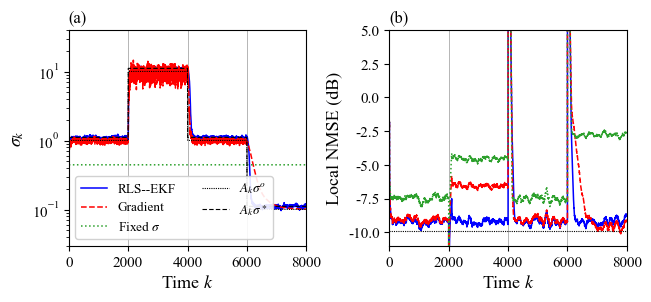

In [6]:
# ============================================================
# Cell 6 (Optional). Staircase tracking plot (a) sigma_k & (b) Local NMSE
# ============================================================
STAIR = (1.0, 10.0, 1.0, 0.1)
STAIR_SEG = 2000
MA_WINDOW = 100
RECOVERY_FACTOR = 1.25

K_st = STAIR_SEG * len(STAIR)
A_k = np.repeat(STAIR, STAIR_SEG)
rngs = child_rngs(30, TRIALS)
x_st = np.stack([r.standard_normal(K_st) for r in rngs]) * A_k
xi_st_t = dither_to_device(np.stack([r.standard_normal((K_st, N_EL), dtype=np.float32) for r in rngs]))

STAIR_OUT = {}
for name, t in TUNED.items():
    STAIR_OUT[name] = simulate(x_st, xi_st_t, t["rule"], lam_f=t["lam"], record_sigma=True, **t["params"])
del xi_st_t


def moving_average(v, n):
    c = np.cumsum(v, axis=-1)
    out = np.empty_like(c)
    out[..., :n] = c[..., :n] / np.arange(1, n + 1)
    out[..., n:] = (c[..., n:] - c[..., :-n]) / n
    return out


STYLE = {
    "RLS--EKF": dict(color="b", ls="-"),
    "Gradient": dict(color="r", ls="--"),
    "Fixed $\\sigma$": dict(color="#2ca02c", ls=":"),
}

set_plot_style()
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(7.2, 2.8))
plt.subplots_adjust(wspace=0.35)
kk = np.arange(1, K_st + 1)

for name in METHODS:
    st = STYLE[name]
    o = STAIR_OUT[name]
    ax_a.plot(kk, o["sigma"].mean(0), color=st["color"], ls=st["ls"], lw=1.1, label=name)
    ma = moving_average((x_st - o["xhat"]) ** 2, MA_WINDOW) / A_k ** 2
    ax_b.plot(kk, 10 * np.log10(ma.mean(0)), color=st["color"], ls=st["ls"], lw=1.1, label=name)

ax_a.plot(kk, A_k * REF["gauss"]["sigma_o"], color="k", lw=0.8, ls=(0, (1, 1)), label=r"$A_k\sigma^o$")
ax_a.plot(kk, A_k * REF["gauss"]["sigma_dag"], color="k", lw=0.8, ls=(0, (4, 2)), label=r"$A_k\sigma^\ast$")
ax_a.set_yscale("log")
ax_a.set(xlim=(0, K_st), ylim=(0.03, 40))
ax_a.set_xlabel(r"Time $k$")
ax_a.set_ylabel(r"$\sigma_k$")
ax_a.set_title("(a)", loc="left", fontsize=12)
ax_a.legend(loc="lower left", ncol=2, framealpha=0.9)

ax_b.axhline(10 * np.log10(REF["gauss"]["zeta_o"]), color="k", lw=0.8, ls=(0, (1, 1)))
ax_b.set(xlim=(0, K_st), ylim=(-11, 5))
ax_b.set_xlabel(r"Time $k$")
ax_b.set_ylabel("Local NMSE (dB)")
ax_b.set_title("(b)", loc="left", fontsize=12)

for ax in (ax_a, ax_b):
    for j in range(1, len(STAIR)):
        ax.axvline(j * STAIR_SEG, color="0.6", lw=0.5, zorder=0)

fig.savefig(os.path.join(OUT_DIR, "Fig_staircase.pdf"), bbox_inches="tight")
plt.show()